# Gaussian Splatting live from a laptop camera

The offline notebook got three things from COLMAP before training started. A webcam gives none of them:

| | Offline (COLMAP) | Live (this notebook) |
|---|---|---|
| Intrinsics $K$ | estimated by SfM | checkerboard calibration once, or a field-of-view guess |
| Poses | bundle adjustment over all images | corner tracking + PnP, frame by frame |
| Initial splats | triangulated SfM points | monocular metric depth on each keyframe |
| Training | 30k steps over all images | a few steps per camera frame, over recent keyframes |

The system splits into a tracking frontend and a mapping backend, like GOFUSION on top of OKVIS2-X:

1. **Track** (every frame, CPU): follow landmarks (corners with a 3D point) with optical flow. PnP against their 3D points gives the pose.
2. **Keyframe** (when the view has changed enough): predict depth, align its scale to the map, add splats where the map is still empty, add landmarks where none are tracked.
3. **Map** (rest of every frame, GPU): your training step on a batch of recent keyframes. Their poses and exposure are refined too.
4. **Refine** (after the run): the offline training loop over all keyframes at full resolution, with grow and prune.

Extra packages: `pip install transformers viser`. The live window needs the GUI build of OpenCV (`opencv-python`, not `opencv-python-headless`); otherwise use `display="notebook"`.

## Setup

In [1]:
import math
import random
import threading
import time
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from gsplat import rasterization
from gsplat.losses import ssim_loss

device = "cuda"

In [2]:
# Camera
CAM_ID = 0                    # /dev/video0
CAP_W, CAP_H = 640, 480       # requested capture size (the camera may choose another one)
HFOV_DEG = 65.0               # horizontal field of view guess, used only without a calibration file
CALIB_FILE = Path("webcam_calib.npz")

# Depth network. Outdoors: "depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf".
DEPTH_MODEL = "depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf"
MAX_DEPTH = 8.0               # ignore predictions farther than this (windows, saturated background), metres

# Tracking and keyframes
MAX_LANDMARKS = 600           # tracked corners
PNP_REPROJ_PX = 2.5           # RANSAC inlier threshold, capture pixels
MIN_INLIERS = 30              # fewer PnP inliers: tracking lost
KF_MIN_INLIERS = 60           # new keyframe when fewer inliers than this, or than half the keyframe's landmarks,
KF_MAX_ROT_DEG = 15.0         # or the view rotated more than this,
KF_MAX_DIST = 0.08            # or the camera moved more than this fraction of the keyframe's median depth

# Mapping
MAP_SCALE = 0.5               # live mapping and display render at 320 x 240
MAP_BUDGET_S = 0.04           # mapping time per camera frame
MAP_BATCH = 2                 # keyframes rendered per mapping step
WINDOW = 8                    # recent keyframes that get most mapping steps
INSERT_STRIDE = 2             # one new splat per 2 x 2 block of mapping pixels
MAX_SPLATS = 300_000
PRUNE_EVERY = 100             # mapping steps
DEPTH_WEIGHT = 0.1
ISO_WEIGHT = 0.05
POSE_LR = 1e-3                # keyframe pose corrections (rad, m)
EXPO_LR = 5e-3                # keyframe exposure corrections

RESULTS_DIR = Path("gs_live_webcam")
RESULTS_DIR.mkdir(exist_ok=True)

## 1. Camera

`Camera` reads frames in a background thread and keeps only the newest one. Without it, OpenCV's capture buffer hands out stale frames whenever a mapping step runs long. `FolderCamera` replays a recorded session with the same interface, so you can tune parameters on the same sequence without holding the laptop up again.

Auto-exposure changes the colour of the same surface between keyframes. The mapping loss compensates per keyframe (Sec. 6), but locking exposure is better. On Linux, list the controls with `v4l2-ctl -d /dev/video0 --list-ctrls`, then for example `v4l2-ctl -d /dev/video0 -c auto_exposure=1 -c exposure_time_absolute=250`. Control names differ between cameras and kernel versions.

In [3]:
class Camera:
    # Webcam frames from a background thread; read() always returns the newest one.

    def __init__(self, cam_id=CAM_ID, width=CAP_W, height=CAP_H):
        self.cap = cv2.VideoCapture(cam_id)
        self.cap.set(cv2.CAP_PROP_FOURCC, cv2.VideoWriter_fourcc(*"MJPG"))  # most webcams reach 30 fps only with MJPG
        self.cap.set(cv2.CAP_PROP_FRAME_WIDTH, width)
        self.cap.set(cv2.CAP_PROP_FRAME_HEIGHT, height)
        ok, self.frame = self.cap.read()
        if not ok:
            raise RuntimeError(f"camera {cam_id} delivers no frames")
        self.id = 0
        self.lock = threading.Lock()
        self.running = True
        self.thread = threading.Thread(target=self._grab, daemon=True)
        self.thread.start()

    def _grab(self):
        while self.running:
            ok, frame = self.cap.read()
            if ok:
                with self.lock:
                    self.frame, self.id = frame, self.id + 1

    def read(self):
        # (frame id, BGR uint8 image). The id only changes when a new frame arrived.
        with self.lock:
            return self.id, self.frame.copy()

    def release(self):
        self.running = False
        self.thread.join(timeout=1)
        self.cap.release()


class FolderCamera:
    # Replays recorded frames (sorted .jpg/.png files) with the Camera interface; returns None at the end.

    def __init__(self, folder):
        self.paths = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in (".jpg", ".png"))
        self.i = -1

    def read(self):
        self.i += 1
        if self.i >= len(self.paths):
            return self.i, None
        return self.i, cv2.imread(str(self.paths[self.i]))

    def release(self):
        pass

### Intrinsics

OpenCV puts pixel centres at integer coordinates; gsplat, like COLMAP, puts them at $+0.5$. Tracking uses OpenCV's matrix $K_\text{cv}$. Rendering uses the same matrix with the principal point shifted by half a pixel:

$$
K_\text{gs} =
\begin{bmatrix}
f_x & 0 & c_x + 0.5 \\
0 & f_y & c_y + 0.5 \\
0 & 0 & 1
\end{bmatrix}
$$

Downscaling to the mapping resolution then works exactly as in the offline notebook: multiply the first row of $K_\text{gs}$ by $s_x$, the second by $s_y$.

Without calibration, the focal length follows from a guessed horizontal field of view $\theta_h$ (laptop webcams: roughly 60–70°), with the principal point in the image centre:

$$
f_x = f_y = \frac{W}{2\tan(\theta_h / 2)}
$$

A wrong $f$ stretches each keyframe's back-projected depth sideways by $f_\text{true} / f$, so keyframes looking in different directions disagree about the geometry. Calibrate once if you can: print the standard 9 × 6 OpenCV checkerboard, or show it full-screen on a phone. Hold it at different distances and tilts, add 15–20 views with SPACE, then press `c`.

In [4]:
# Optional, once per camera: checkerboard calibration. Keys: SPACE add view, c calibrate and save, q quit.
BOARD = (9, 6)  # inner corners
obj = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
obj[:, :2] = np.mgrid[:BOARD[0], :BOARD[1]].T.reshape(-1, 2)  # board coordinates in squares; the unit doesn't matter for K
obj_pts, img_pts = [], []

cam = Camera()
try:
    while True:
        _, frame = cam.read()
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        found, corners = cv2.findChessboardCorners(gray, BOARD, flags=cv2.CALIB_CB_FAST_CHECK)
        vis = frame.copy()
        if found:
            cv2.drawChessboardCorners(vis, BOARD, corners, found)
        cv2.putText(vis, f"{len(img_pts)} views | SPACE add | c calibrate | q quit", (10, 25),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        cv2.imshow("calibration", vis)
        key = cv2.waitKey(1) & 0xFF
        if key == ord(" ") and found:
            corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1),
                                       (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3))
            obj_pts.append(obj)
            img_pts.append(corners)
        elif key == ord("c") and len(img_pts) >= 10:
            H, W = gray.shape
            rms, K, dist, _, _ = cv2.calibrateCamera(obj_pts, img_pts, (W, H), None, None)
            np.savez(CALIB_FILE, K=K, dist=dist, size=np.array([W, H]))
            print(f"RMS reprojection error {rms:.2f} px (good: below 0.5)\n{K}")
            break
        elif key == ord("q"):
            break
finally:
    cam.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)

QFontDatabase: Cannot find font directory /home/boldi/miniconda3/envs/ma/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/boldi/miniconda3/envs/ma/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/boldi/miniconda3/envs/ma/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/boldi/miniconda3/envs/ma/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font director

In [5]:
def load_intrinsics(W, H):
    # K_cv (OpenCV convention) for W x H frames, plus undistortion maps if a calibration file exists.
    if CALIB_FILE.exists():
        c = np.load(CALIB_FILE)
        K0, dist, (W0, H0) = c["K"].copy(), c["dist"], c["size"]
        K0[0] *= W / W0  # calibrated at another resolution: rescale
        K0[1] *= H / H0
        K, _ = cv2.getOptimalNewCameraMatrix(K0, dist, (W, H), alpha=0)  # alpha=0: crop to valid pixels only
        maps = cv2.initUndistortRectifyMap(K0, dist, None, K, (W, H), cv2.CV_16SC2)
        return K, maps
    f = W / 2 / math.tan(math.radians(HFOV_DEG) / 2)
    return np.array([[f, 0, (W - 1) / 2], [0, f, (H - 1) / 2], [0, 0, 1]]), None


def scale_K(K, sx, sy):
    # K_gs for an image downscaled by (sx, sy), as in the offline notebook.
    K = K.clone()
    K[0] *= sx
    K[1] *= sy
    return K

## 2. Metric depth

A single moving camera fixes geometry only up to scale, and only after enough baseline. A monocular depth network gives a dense depth map from a single image, in metres. Depth Anything V2's metric head ends in a sigmoid times $d_\max$ (20 m for the indoor model, 80 m for outdoor). The small model needs a few hundred MB of VRAM in half precision, and it runs only on keyframes.

Each prediction has its own scale error of a few percent. Before a keyframe joins the map, its depth $D$ is rescaled to agree with the rendered map depth $\hat D$ where the map is already solid ($\hat\alpha > 0.95$):

$$
s = \operatorname*{median}_{\mathbf p:\ \hat\alpha(\mathbf p) > 0.95} \frac{\hat D(\mathbf p)}{D(\mathbf p)},
\qquad
D \leftarrow s\,D
$$

The median ignores pixels where the two disagree for other reasons: new objects, floaters, edges. A ratio outside $[0.8, 1.25]$ is more than the network's scale error can explain. It means the map itself is wrong there, so the keyframe keeps its own scale.

Depth at object boundaries is unreliable. The network blurs across the edge, and back-projecting those pixels gives "flying pixels" between foreground and background. A pixel counts as flying when its depth differs by more than 10% from both the nearest and the farthest depth in its neighbourhood ($5 \times 5$ at mapping resolution, $9 \times 9$ at capture resolution). Flying pixels get no splats, no depth supervision and no landmarks. Pixels on either side of the edge keep their depth, so objects don't get a black outline.

In [6]:
def flying_pixels(depth, rel=0.1, k=5):
    # (H, W) bool: pixels between foreground and background (more than rel away from both the nearest
    # and the farthest depth in their k x k neighbourhood).
    d = depth[None, None]
    d_min = -F.max_pool2d(-d, k, stride=1, padding=k // 2)[0, 0]
    d_max = F.max_pool2d(d, k, stride=1, padding=k // 2)[0, 0]
    return (depth - d_min > rel * depth) & (d_max - depth > rel * depth)


def valid_depth(depth, k=5):
    return (depth > 0.05) & (depth < MAX_DEPTH) & ~flying_pixels(depth, k=k)


class MetricDepth:
    # Depth Anything V2 with the metric head: (H, W, 3) RGB in [0, 1] -> (H, W) depth in metres.

    def __init__(self, model_id=DEPTH_MODEL, short_side=518):
        from transformers import AutoModelForDepthEstimation

        self.dtype = torch.float16 if device == "cuda" else torch.float32
        self.model = AutoModelForDepthEstimation.from_pretrained(model_id).to(device, self.dtype).eval()
        self.short_side = short_side  # the resolution the model was trained at
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)  # ImageNet statistics
        self.std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

    @torch.no_grad()
    def __call__(self, rgb):
        H, W = rgb.shape[:2]
        s = self.short_side / min(H, W)
        h, w = round(H * s / 14) * 14, round(W * s / 14) * 14  # multiples of the ViT patch size
        x = F.interpolate(rgb.permute(2, 0, 1)[None], (h, w), mode="bicubic", align_corners=False)
        x = ((x - self.mean) / self.std).to(self.dtype)
        d = self.model(pixel_values=x).predicted_depth[:, None].float()  # (1, 1, h, w)
        return F.interpolate(d, (H, W), mode="bilinear", align_corners=False)[0, 0]

## 3. Splats, rendering, poses

Same parametrization as before, stored in a `ParameterDict` so that splats can be added and removed while training runs. Colours stay plain RGB: each surface is seen from only a few nearby keyframes, so view-dependent colour is poorly constrained.

`render` returns colour, expected depth and accumulated alpha in one pass (`render_mode="RGB+ED"`). With the compositing weights $w_i = \alpha_i \prod_{j<i}(1-\alpha_j)$ and camera-space depths $z_i$:

$$
\hat D(\mathbf p) = \frac{\sum_i w_i z_i}{\sum_i w_i},
\qquad
\hat\alpha(\mathbf p) = \sum_i w_i
$$

Each keyframe $k$ stores the world-to-camera pose from tracking, $T_k^0$, and a learnable correction $\boldsymbol\xi_k = (\boldsymbol\omega_k, \mathbf v_k) \in \mathbb R^6$ (rotation vector, translation). Rendering uses

$$
T_k = \exp\!\left(\boldsymbol\xi_k^\wedge\right) T_k^0,
\qquad
\boldsymbol\xi^\wedge =
\begin{bmatrix}
[\boldsymbol\omega]_\times & \mathbf v \\
\mathbf 0^\top & 0
\end{bmatrix}
\in \mathbb R^{4 \times 4}
$$

Left multiplication applies the correction in the camera frame. `torch.linalg.matrix_exp` computes the exponential exactly and differentiably, and gsplat backpropagates into `viewmats`. The first keyframe defines the world frame (OpenCV: $x$ right, $y$ down, $z$ forward), so its pose stays fixed.

In [7]:
C0 = 0.28209479177387814  # Y_0^0: converts RGB to SH band 0 for export


def new_splats():
    z = lambda *shape: torch.zeros(*shape, device=device)
    return torch.nn.ParameterDict({
        "means": z(0, 3), "quats": z(0, 4), "log_scales": z(0, 3), "logit_opacities": z(0), "colors": z(0, 3),
    })


def render(splats, Ks, viewmats, W, H):
    # Render C cameras at once -> rgb (C, H, W, 3), depth (C, H, W), alpha (C, H, W), meta.
    C = len(viewmats)
    if len(splats["means"]) == 0:
        z = torch.zeros(C, H, W, device=device)
        return z[..., None].repeat(1, 1, 1, 3), z, z, {}
    out, alpha, meta = rasterization(
        means=splats["means"],
        quats=splats["quats"],
        scales=splats["log_scales"].exp(),
        opacities=splats["logit_opacities"].sigmoid(),
        colors=splats["colors"],
        viewmats=viewmats,
        Ks=Ks,
        width=W,
        height=H,
        packed=False,
        render_mode="RGB+ED",
    )
    return out[..., :3], out[..., 3], alpha[..., 0], meta


def se3_exp(xi):
    # (..., 6) twist (omega, v) -> (..., 4, 4) rigid transform.
    w, v = xi[..., :3], xi[..., 3:]
    o = torch.zeros_like(w[..., 0])
    X = torch.stack([
        torch.stack([o, -w[..., 2], w[..., 1], v[..., 0]], -1),
        torch.stack([w[..., 2], o, -w[..., 0], v[..., 1]], -1),
        torch.stack([-w[..., 1], w[..., 0], o, v[..., 2]], -1),
        torch.stack([o, o, o, o], -1),
    ], -2)
    return torch.linalg.matrix_exp(X)


def quat_to_rotmat(q):
    # (N, 4) quaternions (w, x, y, z), any norm -> (N, 3, 3) rotation matrices.
    w, x, y, z = F.normalize(q, dim=-1).unbind(-1)
    return torch.stack([
        1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y),
        2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x),
        2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y),
    ], -1).reshape(-1, 3, 3)


def transform(T, X):
    # Apply a 4x4 transform to (M, 3) points.
    return X @ T[:3, :3].T + T[:3, 3]

### Adding and removing splats mid-training

Adam keeps two moments per parameter entry. When rows are appended (new splats) or dropped (pruning), the same rows must be appended as zeros, or dropped, in `exp_avg` and `exp_avg_sq`. Otherwise the moments belong to the wrong splats. The learning rates are the offline ones; the scene unit is now metres, so `scene_scale = 1`.

In [8]:
def make_optimizer(splats, scene_scale=1.0):
    lrs = {
        "means": 1.6e-4 * scene_scale,
        "quats": 1e-3,
        "log_scales": 5e-3,
        "logit_opacities": 5e-2,
        "colors": 2.5e-3 * C0,
    }
    return torch.optim.Adam([{"params": [splats[k]], "lr": lr, "name": k} for k, lr in lrs.items()], eps=1e-15)


def edit_splats(splats, optimizer, fn):
    # Replace every splat tensor p by fn(p, name, is_moment) and apply the same row edit to its Adam moments.
    for group in optimizer.param_groups:
        name, old = group["name"], group["params"][0]
        new = torch.nn.Parameter(fn(old.detach(), name, False))
        state = optimizer.state.pop(old, {})
        for k in ("exp_avg", "exp_avg_sq"):
            if k in state:
                state[k] = fn(state[k], name, True)
        if state:
            optimizer.state[new] = state
        group["params"][0] = new
        splats[name] = new


def append_splats(splats, optimizer, new):
    edit_splats(splats, optimizer, lambda p, k, is_moment: torch.cat([p, torch.zeros_like(new[k]) if is_moment else new[k]]))


def keep_splats(splats, optimizer, mask):
    edit_splats(splats, optimizer, lambda p, k, is_moment: p[mask])

## 4. Tracking: KLT + PnP

The tracker follows up to 600 landmarks: Shi–Tomasi corners with a 3D point. A landmark is created on a keyframe $k$ by lifting the corner with the keyframe's depth $d$:

$$
\mathbf X_c = d\,K_\text{cv}^{-1}
\begin{bmatrix} u \\ v \\ 1 \end{bmatrix},
\qquad
\mathbf X_w = T_k^{-1}\,\mathbf X_c
$$

$\mathbf X_c$ is stored in keyframe $k$'s camera frame, so when mapping refines $T_k$, its landmarks move with it.

Landmarks outlive their keyframe. A new keyframe keeps every landmark still tracked and only fills the gaps with new corners. Landmarks are lifted with the keyframe's network depth, after scale alignment.

For every new frame:

1. Pyramidal Lucas–Kanade moves each corner from the previous frame to this one. Tracking back must land within 1 px of the start (forward–backward check); otherwise the track is dropped.
2. PnP finds the pose $(R, \mathbf t)$ that minimizes the reprojection error of the surviving 2D–3D pairs, with $\pi(\mathbf x) = (x/z,\ y/z)$:
$$
\min_{R,\,\mathbf t} \sum_i \bigl\lVert \mathbf u_i - \pi\bigl(K_\text{cv}(R\,\mathbf X_i + \mathbf t)\bigr) \bigr\rVert^2
$$
RANSAC rejects tracks that slid along an edge or sit on something that moved. Levenberg–Marquardt then refines the pose on the inliers.
3. If fewer than `MIN_INLIERS` survive, the corners are searched again directly from the keyframe image, with a deeper pyramid. If that fails too, tracking reports LOST until the camera comes back to a view close to the keyframe.

A new keyframe starts when fewer than half of the landmarks tracked at the last keyframe (or fewer than 60) are still inliers, when the view has rotated more than 15°, or when the camera has moved more than 8% of the keyframe's median depth.

In [9]:
LK_PARAMS = dict(winSize=(21, 21), criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))


def detect_corners(gray, n=600, avoid=()):
    # Shi-Tomasi corners at least 10 px apart from each other and from the points in `avoid` -> (M, 2) float32.
    mask = np.full(gray.shape, 255, np.uint8)
    for u, v in avoid:
        cv2.circle(mask, (int(u), int(v)), 10, 0, -1)
    pts = cv2.goodFeaturesToTrack(gray, maxCorners=n, qualityLevel=0.01, minDistance=10, mask=mask) if n > 0 else None
    return np.zeros((0, 2), np.float32) if pts is None else pts[:, 0]


def klt(gray0, gray1, pts0, max_level=3):
    # Move pts0 from gray0 to gray1. Returns the new points and a mask of tracks that pass the forward-backward check.
    if len(pts0) == 0:
        return pts0, np.zeros(0, bool)
    p0 = pts0.reshape(-1, 1, 2)
    p1, ok1, _ = cv2.calcOpticalFlowPyrLK(gray0, gray1, p0, None, maxLevel=max_level, **LK_PARAMS)
    p0_back, ok2, _ = cv2.calcOpticalFlowPyrLK(gray1, gray0, p1, None, maxLevel=max_level, **LK_PARAMS)
    fb_err = np.linalg.norm(p0_back - p0, axis=-1)[:, 0]
    return p1[:, 0], (ok1[:, 0] == 1) & (ok2[:, 0] == 1) & (fb_err < 1.0)


def solve_pnp(X, uv, K, viewmat_guess):
    # World points X (M, 3) seen at pixels uv (M, 2) -> world-to-camera viewmat (4, 4) and inlier mask, or (None, None).
    if len(X) < MIN_INLIERS:
        return None, None
    X, uv = X.astype(np.float64), uv.astype(np.float64)
    rvec, _ = cv2.Rodrigues(viewmat_guess[:3, :3])
    tvec = viewmat_guess[:3, 3:].copy()
    ok, rvec, tvec, inl = cv2.solvePnPRansac(
        X, uv, K, None, rvec=rvec, tvec=tvec, useExtrinsicGuess=True, iterationsCount=100,
        reprojectionError=PNP_REPROJ_PX, confidence=0.999, flags=cv2.SOLVEPNP_ITERATIVE)
    if not ok or inl is None or len(inl) < MIN_INLIERS:
        return None, None
    inl = inl[:, 0]
    rvec, tvec = cv2.solvePnPRefineLM(X[inl], uv[inl], K, None, rvec, tvec)
    T = np.eye(4)
    T[:3, :3], T[:3, 3] = cv2.Rodrigues(rvec)[0], tvec[:, 0]
    mask = np.zeros(len(X), bool)
    mask[inl] = True
    return T, mask


class Tracker:
    # Frontend: tracks landmarks from frame to frame and solves PnP.
    # A landmark is a corner with a 3D point, stored in the camera frame of the keyframe that created it (its anchor).

    def __init__(self, K_cv):
        self.K = K_cv
        self.X = np.zeros((0, 3))                 # (L, 3) landmark points in their anchor keyframe's camera frame
        self.anchor = np.zeros(0, int)            # (L,) index of the anchor keyframe
        self.uv = np.zeros((0, 2), np.float32)    # (M, 2) current pixel positions of the tracked landmarks
        self.ids = np.zeros(0, int)               # (M,) their landmark indices
        self.kf_id, self.prev_gray = None, None

    def world_points(self, ids, keyframes):
        # Landmarks in world coordinates, with the current (refined) pose of each anchor keyframe.
        X = np.empty((len(ids), 3))
        for a in np.unique(self.anchor[ids]):
            sel = self.anchor[ids] == a
            X[sel] = transform(np.linalg.inv(keyframes[a].viewmat_np()), self.X[ids][sel])
        return X

    def add_keyframe(self, kf_id, gray, uv_new, X_new):
        # Keep the landmarks still tracked, add new ones anchored in keyframe kf_id.
        self.X = np.concatenate([self.X[self.ids], X_new])
        self.anchor = np.concatenate([self.anchor[self.ids], np.full(len(X_new), kf_id)])
        self.uv = np.concatenate([self.uv, uv_new]).astype(np.float32)
        self.ids = np.arange(len(self.uv))
        self.kf_id, self.kf_gray, self.kf_uv, self.kf_ids = kf_id, gray, self.uv.copy(), self.ids.copy()
        self.prev_gray = gray

    def track(self, gray, viewmat_guess, keyframes):
        # Pose of this frame (world -> camera) and number of PnP inliers, or (None, 0) if lost.
        attempts = [(self.kf_gray, self.kf_uv, self.kf_ids, 5)]       # fallback: search from the keyframe image
        if self.prev_gray is not None:
            attempts.insert(0, (self.prev_gray, self.uv, self.ids, 3))  # usual case: from the previous frame
        for src_gray, src_uv, src_ids, levels in attempts:
            uv, ok = klt(src_gray, gray, src_uv, levels)
            ids = src_ids[ok]
            T, inl = solve_pnp(self.world_points(ids, keyframes), uv[ok], self.K, viewmat_guess)
            if T is not None:
                self.uv, self.ids, self.prev_gray = uv[ok][inl], ids[inl], gray
                return T, int(inl.sum())
        self.prev_gray = None  # lost: the next frame searches from the keyframe image directly
        return None, 0

## 5. Keyframes and splat insertion

New splats go where the map, rendered from the new keyframe, is missing:

- $\hat\alpha < 0.5$: nothing mapped there yet, or
- $D < 0.75\,\hat D$: the observed surface lies clearly in front of the map (a new object).

This is the role of GOFUSION's "Gaussians only in newly occupied voxels": surfaces that are already mapped don't get a second layer.

One splat per $k \times k$ block of mapping pixels ($k$ = `INSERT_STRIDE`), at the back-projected depth of the block's centre pixel, with that pixel's colour. Neighbouring samples are $\Delta = k\,d / f$ apart in the world. An isotropic $\sigma = \Delta / 2$ with opacity $0.7$ gives an accumulated alpha of about $0.7$ even midway between samples, so the next keyframe sees this region as covered and doesn't fill it again.

Compare the offline initialization, which used the RMS distance to the 3 nearest SfM points: there, splat size followed the SfM point density. Here it follows the pixel grid, so splats grow with depth.

In [10]:
@dataclass
class Keyframe:
    rgb: torch.Tensor          # (h, w, 3) in [0, 1], mapping resolution
    depth: torch.Tensor        # (h, w) metric depth aligned to the map, 0 = invalid
    viewmat0: torch.Tensor     # (4, 4) world -> camera from tracking
    delta: torch.Tensor        # (6,) learnable pose correction (omega, v)
    expo: torch.Tensor         # (2, 3) learnable exposure: log-gain and bias per channel
    image: np.ndarray          # (H, W, 3) uint8 RGB, capture resolution, for the offline refinement
    depth_full: torch.Tensor   # (H, W) float16 on the CPU, aligned depth at capture resolution
    median_depth: float

    @property
    def viewmat(self):
        return se3_exp(self.delta) @ self.viewmat0

    def viewmat_np(self):
        return self.viewmat.detach().double().cpu().numpy()


def resize(img, h, w):
    # (H, W, C) -> (h, w, C) by area averaging.
    return F.interpolate(img.permute(2, 0, 1)[None], (h, w), mode="area")[0].permute(1, 2, 0)

## 6. Mapping

Each mapping step renders a batch of keyframes. The newest keyframe is in half the batches; the others come mostly from the last `WINDOW` keyframes, and sometimes from all of them, so older parts of the map keep their supervision while the window moves on.

The loss is the offline photometric loss, plus a depth term and an isotropy term:

$$
\mathcal L
= 0.8\,\mathcal L_1 + 0.2\,\mathcal L_\text{D-SSIM}
+ \lambda_d \operatorname*{mean}_{\mathbf p} \frac{\lvert \hat D(\mathbf p) - D(\mathbf p) \rvert}{D(\mathbf p)}
+ \lambda_\text{iso} \operatorname*{mean}_{i,j} \bigl\lvert \log s_{ij} - \overline{\log s_i} \bigr\rvert
$$

- **Depth**: with a few nearby views per surface, the photometric error alone is also satisfied by floaters in front of the camera. Dividing by $D$ weights near and far surfaces equally.
- **Isotropy** (from MonoGS): with narrow baselines, needle-shaped splats fit the training views and break between them. $\overline{\log s_i}$ is the mean log scale of splat $i$ over its three axes.
- **Exposure**: each keyframe $k$ except the first learns a gain and bias per channel, $\hat C \leftarrow e^{\mathbf a_k} \odot \hat C + \mathbf b_k$, so that auto-exposure doesn't get baked into the splat colours.

Every 100 steps, splats with opacity below 0.005, or larger than 10% of the scene scale, are pruned. The scene scale is the median keyframe depth: for a camera looking out into a room, it's the typical distance to the surfaces.

In [11]:
def mapping_loss(splats, rgb, depth, gt_rgb, gt_depth, expo):
    # rgb, gt_rgb: (B, h, w, 3); depth, gt_depth: (B, h, w); expo: (B, 2, 3).
    rgb = rgb * expo[:, None, None, 0].exp() + expo[:, None, None, 1]
    l1 = (rgb - gt_rgb).abs().mean()
    d_ssim = ssim_loss(rgb.permute(0, 3, 1, 2), gt_rgb.permute(0, 3, 1, 2))
    valid = gt_depth > 0
    l_depth = ((depth - gt_depth).abs() / gt_depth.clamp_min(1e-3) * valid).sum() / valid.sum().clamp_min(1)
    log_s = splats["log_scales"]
    l_iso = (log_s - log_s.mean(-1, keepdim=True)).abs().mean()
    return torch.lerp(l1, d_ssim, 0.2) + DEPTH_WEIGHT * l_depth + ISO_WEIGHT * l_iso


class Mapper:
    # Backend: keyframes, splats, and the optimization that fits the splats to the keyframes.

    def __init__(self, K_gs, W, H):
        self.W, self.H = W, H
        self.w, self.h = round(W * MAP_SCALE), round(H * MAP_SCALE)
        self.K_full = torch.tensor(K_gs, dtype=torch.float32, device=device)
        self.K_map = scale_K(self.K_full, self.w / W, self.h / H)
        self.splats = new_splats()
        self.opt = make_optimizer(self.splats)
        self.pose_opt = None  # created with the second keyframe: the first one stays fixed
        self.keyframes = []
        self.n_steps = 0
        self.loss = torch.tensor(float("nan"))

    @property
    def scene_scale(self):
        return float(np.median([kf.median_depth for kf in self.keyframes])) if self.keyframes else 1.0

    @torch.no_grad()
    def render_view(self, viewmat):
        rgb, depth, alpha, _ = render(self.splats, self.K_map[None], viewmat[None], self.w, self.h)
        return rgb[0], depth[0], alpha[0]

    @torch.no_grad()
    def add_keyframe(self, image, rgb_full, depth_full, viewmat):
        # image: (H, W, 3) uint8; rgb_full: the same on the GPU in [0, 1]; depth_full: network depth; viewmat: numpy.
        # Returns the keyframe and the depth to lift new landmarks with (capture resolution).
        rgb = resize(rgb_full, self.h, self.w)
        depth = resize(depth_full[..., None], self.h, self.w)[..., 0]
        viewmat = torch.tensor(viewmat, dtype=torch.float32, device=device)
        _, map_depth, map_alpha = self.render_view(viewmat)

        # Align the network's depth scale to the map where the map is solid (Sec. 2).
        valid = valid_depth(depth)
        solid = valid & (map_alpha > 0.95)
        if solid.float().mean() > 0.05:  # enough overlap to measure the scale
            s = (map_depth[solid] / depth[solid]).median()
            if 0.8 < s < 1.25:  # outside: the map is wrong here (floaters), don't let it rescale the keyframe
                depth, depth_full = depth * s, depth_full * s
        depth = depth * valid
        depth_full = depth_full * valid_depth(depth_full, k=9)

        first = not self.keyframes
        kf = Keyframe(
            rgb=rgb,
            depth=depth,
            viewmat0=viewmat,
            delta=torch.zeros(6, device=device, requires_grad=not first),
            expo=torch.zeros(2, 3, device=device, requires_grad=not first),
            image=image,
            depth_full=depth_full.half().cpu(),
            median_depth=depth[valid].median().item() if valid.any() else 1.0,
        )
        if not first:
            groups = [{"params": [kf.delta], "lr": POSE_LR}, {"params": [kf.expo], "lr": EXPO_LR}]
            if self.pose_opt is None:
                self.pose_opt = torch.optim.Adam(groups)
            else:
                for g in groups:
                    self.pose_opt.add_param_group(g)
        self.keyframes.append(kf)
        self.insert(kf, map_depth, map_alpha)
        return kf, depth_full

    @torch.no_grad()
    def insert(self, kf, map_depth, map_alpha):
        # Add splats where the map, seen from this keyframe, is missing (Sec. 5).
        k = INSERT_STRIDE
        block = (slice(k // 2, None, k), slice(k // 2, None, k))  # centre pixel of each k x k block
        d = kf.depth[block]
        new = (d > 0) & ((map_alpha[block] < 0.5) | (d < 0.75 * map_depth[block]))
        rows, cols = torch.nonzero(new, as_tuple=True)
        v = (rows * k + k // 2).float() + 0.5  # pixel centres, gsplat convention
        u = (cols * k + k // 2).float() + 0.5
        z = d[new]
        fx, fy, cx, cy = self.K_map[0, 0], self.K_map[1, 1], self.K_map[0, 2], self.K_map[1, 2]
        X_cam = torch.stack([(u - cx) / fx * z, (v - cy) / fy * z, z], -1)
        means = transform(torch.linalg.inv(kf.viewmat), X_cam)

        n = min(len(means), MAX_SPLATS - len(self.splats["means"]))
        if n <= 0:
            return
        idx = torch.randperm(len(means), device=device)[:n]
        sigma = 0.5 * k * z[idx] / fx  # half the spacing between neighbouring samples
        append_splats(self.splats, self.opt, {
            "means": means[idx],
            "quats": torch.tensor([1.0, 0.0, 0.0, 0.0], device=device).repeat(n, 1),
            "log_scales": sigma.log()[:, None].repeat(1, 3),
            "logit_opacities": torch.full((n,), math.log(0.7 / 0.3), device=device),
            "colors": kf.rgb[block][new][idx],
        })

    def sample_keyframes(self):
        # Newest keyframe in half the batches; the rest mostly from the last WINDOW keyframes, sometimes from all.
        n = len(self.keyframes)
        recent = range(max(0, n - WINDOW), n)
        ids = {n - 1 if random.random() < 0.5 else random.choice(recent)}
        while len(ids) < min(MAP_BATCH, n):
            ids.add(random.choice(recent if random.random() < 0.7 else range(n)))
        return [self.keyframes[i] for i in ids]

    def step(self):
        if len(self.splats["means"]) == 0:
            return
        kfs = self.sample_keyframes()
        viewmats = torch.stack([kf.viewmat for kf in kfs])
        rgb, depth, _, _ = render(self.splats, self.K_map.repeat(len(kfs), 1, 1), viewmats, self.w, self.h)
        loss = mapping_loss(
            self.splats, rgb, depth,
            torch.stack([kf.rgb for kf in kfs]),
            torch.stack([kf.depth for kf in kfs]),
            torch.stack([kf.expo for kf in kfs]),
        )
        self.opt.zero_grad(set_to_none=True)
        if self.pose_opt:
            self.pose_opt.zero_grad(set_to_none=True)
        loss.backward()
        self.opt.step()
        if self.pose_opt:
            self.pose_opt.step()
        self.loss = loss.detach()
        self.n_steps += 1
        if self.n_steps % PRUNE_EVERY == 0:
            self.prune()

    @torch.no_grad()
    def prune(self):
        keep = (self.splats["logit_opacities"].sigmoid() > 0.005) & \
               (self.splats["log_scales"].exp().amax(-1) < 0.1 * self.scene_scale)
        if not keep.all():
            keep_splats(self.splats, self.opt, keep)

## 7. The live loop

`LiveGS` connects the two halves. Per camera frame, `process` tracks and, if needed, adds a keyframe; `map` spends the rest of the frame's time budget on mapping steps. The window shows the camera with the tracked corners, the map rendered from the tracked pose, and its depth.

`LiveViewer` streams the splats and the keyframe cameras to viser every two seconds, so you can orbit the growing map in the browser while scanning. The splats are rendered by viser in the browser, not by gsplat.

In [12]:
def colorize_depth(depth, d_max):
    out = cv2.applyColorMap((np.clip(depth / d_max, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_TURBO)
    out[depth <= 0] = 0
    return out


def put_text(img, text, org=(8, 20)):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)


class LiveGS:
    def __init__(self, K_cv, W, H, depth_net, undistort_maps=None):
        self.K_cv, self.W, self.H = K_cv, W, H
        self.K_gs = K_cv.copy()
        self.K_gs[:2, 2] += 0.5  # pixel centres at +0.5 (Sec. 1)
        self.depth_net, self.maps = depth_net, undistort_maps
        self.reset()

    def reset(self):
        self.mapper = Mapper(self.K_gs, self.W, self.H)
        self.tracker = Tracker(self.K_cv)
        self.viewmat = np.eye(4)  # current camera, world -> camera
        self.trajectory = []      # viewmat of every tracked frame
        self.frame, self.status = None, "starting"

    def process(self, bgr):
        # Track one camera frame; add a keyframe if the view has changed enough.
        if self.maps is not None:
            bgr = cv2.remap(bgr, *self.maps, cv2.INTER_LINEAR)
        self.frame = bgr
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        if not self.mapper.keyframes:
            self.add_keyframe(bgr, gray)
            if len(self.tracker.kf_uv) < 2 * MIN_INLIERS:
                self.reset()
                self.status = "too little texture: point the camera at something with detail"
            else:
                self.trajectory.append(self.viewmat)
            return
        T, n_inliers = self.tracker.track(gray, self.viewmat, self.mapper.keyframes)
        if T is None:
            self.status = "LOST: move back to where tracking was good"
            return
        self.viewmat = T
        self.trajectory.append(T)
        self.status = f"tracking {n_inliers} corners"
        if self.need_keyframe(n_inliers):
            self.add_keyframe(bgr, gray)

    def need_keyframe(self, n_inliers):
        kf = self.mapper.keyframes[self.tracker.kf_id]
        rel = self.viewmat @ np.linalg.inv(kf.viewmat_np())  # keyframe camera -> current camera
        angle = math.degrees(math.acos(np.clip((np.trace(rel[:3, :3]) - 1) / 2, -1, 1)))
        dist = np.linalg.norm(rel[:3, 3])  # distance between the two camera centres
        return (n_inliers < max(KF_MIN_INLIERS, 0.5 * len(self.tracker.kf_uv))
                or angle > KF_MAX_ROT_DEG
                or dist > KF_MAX_DIST * kf.median_depth)

    def add_keyframe(self, bgr, gray):
        image = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rgb_full = torch.from_numpy(image).to(device).float() / 255
        kf, lift_depth = self.mapper.add_keyframe(image, rgb_full, self.depth_net(rgb_full), self.viewmat)

        # New landmarks away from the ones still tracked, lifted to 3D in the keyframe's camera frame (Sec. 4).
        t = self.tracker
        uv = detect_corners(gray, n=MAX_LANDMARKS - len(t.uv), avoid=t.uv)
        cols = np.clip(np.round(uv[:, 0]).astype(int), 0, self.W - 1)  # OpenCV: pixel centres at integers
        rows = np.clip(np.round(uv[:, 1]).astype(int), 0, self.H - 1)
        d = lift_depth.cpu().numpy()[rows, cols]
        uv, d = uv[d > 0], d[d > 0]
        fx, fy, cx, cy = self.K_cv[0, 0], self.K_cv[1, 1], self.K_cv[0, 2], self.K_cv[1, 2]
        X_cam = np.stack([(uv[:, 0] - cx) / fx * d, (uv[:, 1] - cy) / fy * d, d], -1)
        t.add_keyframe(len(self.mapper.keyframes) - 1, gray, uv, X_cam)

    def map(self, budget_s=MAP_BUDGET_S, steps=None):
        # Mapping steps for budget_s seconds (at least one), or exactly `steps` steps.
        if not self.mapper.keyframes:
            return
        t_end = time.perf_counter() + budget_s
        n = 0
        while (n < steps) if steps is not None else (n == 0 or time.perf_counter() < t_end):
            self.mapper.step()
            n += 1

    @torch.no_grad()
    def visualize(self, fps, height=360):
        # Camera with tracked corners | map rendered from the tracked pose | rendered depth.
        cam = self.frame.copy()
        for u, v in self.tracker.uv:
            cv2.circle(cam, (int(u), int(v)), 2, (0, 255, 0), -1)
        m = self.mapper
        if m.keyframes:
            rgb, depth, _ = m.render_view(torch.tensor(self.viewmat, dtype=torch.float32, device=device))
            render_bgr = cv2.cvtColor((rgb.clamp(0, 1) * 255).byte().cpu().numpy(), cv2.COLOR_RGB2BGR)
            depth_bgr = colorize_depth(depth.cpu().numpy(), 2 * m.scene_scale)
        else:
            render_bgr = depth_bgr = np.zeros_like(cam)
        width = round(height * self.W / self.H)
        mosaic = np.hstack([cv2.resize(p, (width, height)) for p in (cam, render_bgr, depth_bgr)])
        put_text(mosaic, self.status)
        put_text(mosaic, f"{fps:4.1f} fps | {len(m.keyframes)} keyframes | {len(m.splats['means']):,} splats | "
                         f"loss {m.loss.item():.3f}", (8, height - 10))
        return mosaic


class Display:
    # "window": OpenCV window with keys (q quit, r reset, SPACE pause tracking); "notebook": inline image; None: nothing.

    def __init__(self, mode):
        self.mode = mode
        if mode == "notebook":
            import ipywidgets
            from IPython.display import display

            self.widget = ipywidgets.Image(format="jpeg")
            display(self.widget)

    def show(self, img):
        if self.mode == "window":
            cv2.imshow("live gaussian splatting", img)
            key = cv2.waitKey(1) & 0xFF
            return chr(key) if key != 255 else ""
        if self.mode == "notebook":
            self.widget.value = cv2.imencode(".jpg", img)[1].tobytes()
        return ""

    def close(self):
        if self.mode == "window":
            cv2.destroyAllWindows()
            cv2.waitKey(1)


class LiveViewer:
    # Streams splats and keyframe cameras to viser: open http://localhost:<port>.

    def __init__(self, port=8080, every_s=2.0):
        import viser
        import viser.transforms as vtf

        self.vtf = vtf
        self.server = viser.ViserServer(port=port)
        self.server.scene.set_up_direction("-y")  # OpenCV world: y points down
        self.every_s, self.t_last = every_s, 0.0

    def frustum(self, name, viewmat, K, W, H, color, scale):
        c2w = np.linalg.inv(viewmat)
        self.server.scene.add_camera_frustum(
            name, fov=2 * math.atan(H / 2 / K[1, 1]), aspect=W / H, scale=scale, color=color,
            wxyz=self.vtf.SO3.from_matrix(c2w[:3, :3]).wxyz, position=c2w[:3, 3])

    @torch.no_grad()
    def update(self, slam, force=False):
        if not force and time.perf_counter() - self.t_last < self.every_s:
            return
        self.t_last = time.perf_counter()
        sp, m = slam.mapper.splats, slam.mapper
        if len(sp["means"]) == 0:
            return
        M = quat_to_rotmat(sp["quats"]) * sp["log_scales"].exp()[:, None, :]  # R diag(s)
        self.server.scene.add_gaussian_splats(
            "/splats",
            centers=sp["means"].cpu().numpy(),
            covariances=(M @ M.transpose(1, 2)).cpu().numpy(),
            rgbs=sp["colors"].clamp(0, 1).cpu().numpy(),
            opacities=sp["logit_opacities"].sigmoid()[:, None].cpu().numpy(),
        )
        scale = 0.1 * m.scene_scale
        for i, kf in enumerate(m.keyframes):
            self.frustum(f"/keyframes/{i}", kf.viewmat_np(), slam.K_cv, slam.W, slam.H, (120, 120, 120), scale)
        self.frustum("/camera", slam.viewmat, slam.K_cv, slam.W, slam.H, (255, 0, 0), scale)


def run_live(cam, slam, display="window", viewer=None, map_steps=None, record_dir=None):
    # Main loop. Stop with q in the window, or by interrupting the kernel.
    # map_steps: fixed mapping steps per frame instead of the time budget (reproducible replays).
    # record_dir: save every raw frame there, to replay the session later with FolderCamera.
    screen = Display(display)
    if record_dir is not None:
        Path(record_dir).mkdir(parents=True, exist_ok=True)
    last_id, paused, fps, t_prev = None, False, 0.0, time.perf_counter()
    try:
        while True:
            fid, bgr = cam.read()
            if bgr is None:  # end of a recording
                break
            if fid != last_id and not paused:
                last_id = fid
                if record_dir is not None:  # timestamps keep the order across re-runs
                    cv2.imwrite(str(Path(record_dir) / f"{time.time_ns()}.jpg"), bgr)
                slam.process(bgr)
            slam.map(steps=map_steps)
            t = time.perf_counter()
            fps, t_prev = 0.9 * fps + 0.1 / (t - t_prev), t
            key = screen.show(slam.visualize(fps)) if display and slam.frame is not None else ""
            if viewer is not None:
                viewer.update(slam)
            if key == "q":
                break
            if key == "r":
                slam.reset()
            if key == " ":
                paused = not paused
    except KeyboardInterrupt:
        pass
    finally:
        cam.release()
        screen.close()
        if viewer is not None:
            viewer.update(slam, force=True)

### Run

Load the depth network once (the first run downloads ~100 MB from Hugging Face):

In [13]:
depth_net = MetricDepth()

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Then scan. What helps:

- Start facing something with texture, about 0.5–3 m away. The first frame defines the world frame.
- Move slowly and smoothly, and translate as well as rotate: sideways steps give the map views from different angles.
- Keep part of the previous view in the frame. If the status says LOST, move back to where it was last good.
- SPACE pauses tracking: mapping keeps running, so the map sharpens while you hold still. `r` starts over, `q` stops.
- Open http://localhost:8080 to watch the map grow in 3D.

Re-running the next cell continues the same map. Tracking resumes from the last keyframe, so start from that view.

640 x 480, fx = 502.3, field-of-view guess


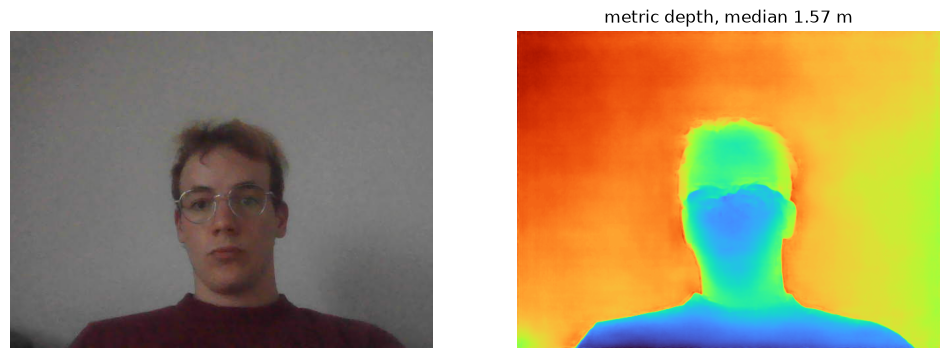

╭────── viser (listening *:8080) ───────╮
│             ╷                         │
│   HTTP      │ http://localhost:8080   │
│   Websocket │ ws://localhost:8080     │
│             ╵                         │
╰───────────────────────────────────────╯

In [14]:
cam = Camera()
_, bgr = cam.read()
cam.release()
H, W = bgr.shape[:2]
K_cv, maps = load_intrinsics(W, H)
print(f"{W} x {H}, fx = {K_cv[0, 0]:.1f}, {'calibrated' if maps is not None else 'field-of-view guess'}")

# Sanity check: one frame and its predicted depth.
rgb = cv2.cvtColor(bgr if maps is None else cv2.remap(bgr, *maps, cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
depth = depth_net(torch.from_numpy(rgb).to(device).float() / 255).cpu()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(rgb)
axes[1].imshow(depth, cmap="turbo")
axes[1].set_title(f"metric depth, median {depth.median():.2f} m")
for ax in axes:
    ax.axis("off")
plt.show()

slam = LiveGS(K_cv, W, H, depth_net, maps)
viewer = LiveViewer(port=8080)

In [ ]:
run_live(Camera(), slam, display="window", viewer=viewer, record_dir=RESULTS_DIR / "frames")
print(f"{len(slam.mapper.keyframes)} keyframes, {len(slam.mapper.splats['means']):,} splats, "
      f"{slam.mapper.n_steps} mapping steps")

(viser) Connection opened (0, 1 total), 475 persistent messages

166 keyframes, 96,087 splats, 3215 mapping steps


(viser) Connection closed (0, 0 total)

Replay the recorded session, for example after changing a parameter. Re-runs append to the same recording, and `map_steps` makes the replay independent of GPU speed.

```python
replay = LiveGS(K_cv, W, H, depth_net, maps)
run_live(FolderCamera(RESULTS_DIR / "frames"), replay, display="window", map_steps=5)
```

## 8. Results

Keyframe PSNR measures fit to the training views, so it's an upper bound on quality. Novel views are where floaters and gaps show up: check those in the viewer.

In [ ]:
@torch.no_grad()
def keyframe_psnr(mapper, scale=None):
    # Mean PSNR over all keyframes, exposure-corrected, at mapping resolution (or capture resolution x scale).
    psnrs = []
    for kf in mapper.keyframes:
        if scale is None:
            K, w, h, gt = mapper.K_map, mapper.w, mapper.h, kf.rgb
        else:
            w, h = round(mapper.W * scale), round(mapper.H * scale)
            K = scale_K(mapper.K_full, w / mapper.W, h / mapper.H)
            gt = resize(torch.from_numpy(kf.image).to(device).float() / 255, h, w)
        rgb, _, _, _ = render(mapper.splats, K[None], kf.viewmat[None], w, h)
        rgb = (rgb[0] * kf.expo[0].exp() + kf.expo[1]).clamp(0, 1)
        psnrs.append(-10 * torch.log10(((rgb - gt) ** 2).mean()).item())
    return float(np.mean(psnrs))


@torch.no_grad()
def show_keyframes(mapper, n=4):
    ids = np.linspace(0, len(mapper.keyframes) - 1, n).round().astype(int)
    fig, axes = plt.subplots(3, n, figsize=(4 * n, 9), squeeze=False)
    for col, i in enumerate(ids):
        kf = mapper.keyframes[i]
        rgb, depth, _, _ = render(mapper.splats, mapper.K_map[None], kf.viewmat[None], mapper.w, mapper.h)
        rgb = (rgb[0] * kf.expo[0].exp() + kf.expo[1]).clamp(0, 1)
        for row, (im, title) in enumerate([(kf.rgb, f"keyframe {i}"), (rgb, "render"), (depth[0], "rendered depth")]):
            axes[row, col].imshow(im.cpu(), cmap="turbo" if row == 2 else None)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")
    plt.tight_layout()
    plt.show()


def save_ckpt(splats, path):
    # gsplat checkpoint, readable by examples/simple_viewer.py --ckpt.
    s = {k: v.detach() for k, v in splats.items()}
    torch.save({"splats": {
        "means": s["means"],
        "quats": s["quats"],
        "scales": s["log_scales"],
        "opacities": s["logit_opacities"],
        "sh0": ((s["colors"] - 0.5) / C0)[:, None],         # (N, 1, 3): band 0 only
        "shN": torch.zeros(len(s["means"]), 0, 3, device=s["means"].device),
    }}, path)


def save_ply(splats, path):
    # Standard 3DGS .ply with SH degree 0 (SuperSplat, other web viewers). World frame: OpenCV, y down.
    s = {k: v.detach().cpu().numpy().astype(np.float32) for k, v in splats.items()}
    cols = [s["means"], np.zeros_like(s["means"]), (s["colors"] - 0.5) / C0, s["logit_opacities"][:, None],
            s["log_scales"], s["quats"] / np.linalg.norm(s["quats"], axis=1, keepdims=True)]
    names = ["x", "y", "z", "nx", "ny", "nz", "f_dc_0", "f_dc_1", "f_dc_2", "opacity",
             "scale_0", "scale_1", "scale_2", "rot_0", "rot_1", "rot_2", "rot_3"]
    data = np.concatenate(cols, axis=1).astype("<f4")
    header = (f"ply\nformat binary_little_endian 1.0\nelement vertex {len(data)}\n"
              + "".join(f"property float {n}\n" for n in names) + "end_header\n")
    with open(path, "wb") as f:
        f.write(header.encode())
        f.write(data.tobytes())

In [ ]:
print(f"keyframe PSNR (live): {keyframe_psnr(slam.mapper):.2f} dB")
show_keyframes(slam.mapper)
save_ckpt(slam.mapper.splats, RESULTS_DIR / "splats_live.pt")

## 9. Offline refinement

Live mapping is at mapping resolution with a few steps per keyframe. After the run, all keyframes are available at capture resolution, so the offline training loop can finish the job, as in GOFUSION's global stage. It's the loop from the offline notebook with the live loss (depth, isotropy, exposure) and pose refinement kept on:

- Each step renders one random keyframe at capture resolution (`scale=0.5` if VRAM runs out).
- Grow and prune as in the offline notebook, every 100 steps until `grow_until`. The thresholds use the median keyframe depth as scene scale.

There are no held-out views. Every frame that became a keyframe is training data, so keyframe PSNR measures fit, not generalization.

In [ ]:
@torch.no_grad()
def grow(splats, optimizer, grad_avg, scene_scale, grad_thresh=2e-4, small=0.01):
    # Clone small and split large splats whose 2D centres the loss pulls on hard (as in the offline notebook).
    hot = grad_avg > grad_thresh
    scales = splats["log_scales"].exp()
    is_small = scales.amax(-1) <= small * scene_scale
    clone, split = hot & is_small, hot & ~is_small

    # Split: two children sampled from the parent Gaussian, 1.6x smaller; the parent is removed.
    R = quat_to_rotmat(splats["quats"][split])                                              # (n, 3, 3)
    offsets = (R @ (torch.randn(2, len(R), 3, 1, device=device) * scales[split][..., None]))[..., 0]  # (2, n, 3)
    children = {k: v[split].repeat(2, *[1] * (v.dim() - 1)) for k, v in splats.items()}
    children["means"] = (splats["means"][split] + offsets).reshape(-1, 3)
    children["log_scales"] = children["log_scales"] - math.log(1.6)

    new = {k: torch.cat([v[clone], children[k]]) for k, v in splats.items()}
    keep = torch.cat([~split, torch.ones(len(new["means"]), dtype=torch.bool, device=device)])
    append_splats(splats, optimizer, new)
    keep_splats(splats, optimizer, keep)
    return int(clone.sum()), int(split.sum())


def refine_offline(mapper, steps=3000, scale=1.0, grow_until=2000, refine_every=100):
    # Joint splat + keyframe pose refinement over all keyframes at capture resolution x scale.
    w, h = round(mapper.W * scale), round(mapper.H * scale)
    K = scale_K(mapper.K_full, w / mapper.W, h / mapper.H)
    splats, kfs = mapper.splats, mapper.keyframes
    grad2d = torch.zeros(len(splats["means"]), device=device)
    count = torch.zeros(len(splats["means"]), device=device)

    for step in range(steps):
        kf = random.choice(kfs)
        gt = torch.from_numpy(kf.image).to(device).float() / 255
        gt_depth = kf.depth_full.to(device).float()
        if scale != 1.0:
            gt = resize(gt, h, w)
            gt_depth = F.interpolate(gt_depth[None, None], (h, w), mode="nearest")[0, 0]

        rgb, depth, _, meta = render(splats, K[None], kf.viewmat[None], w, h)
        meta["means2d"].retain_grad()
        loss = mapping_loss(splats, rgb, depth, gt[None], gt_depth[None], kf.expo[None])
        mapper.opt.zero_grad(set_to_none=True)
        if mapper.pose_opt:
            mapper.pose_opt.zero_grad(set_to_none=True)
        loss.backward()
        mapper.opt.step()
        if mapper.pose_opt:
            mapper.pose_opt.step()

        if step < grow_until:
            radii = meta["radii"][0]
            visible = (radii > 0).all(-1) if radii.dim() == 2 else radii > 0
            g = meta["means2d"].grad[0] * torch.tensor([w / 2, h / 2], device=device)  # pixels -> NDC
            grad2d[visible] += g[visible].norm(dim=-1)
            count[visible] += 1
            if (step + 1) % refine_every == 0:
                n_clone, n_split = grow(splats, mapper.opt, grad2d / count.clamp_min(1), mapper.scene_scale)
                mapper.prune()
                grad2d = torch.zeros(len(splats["means"]), device=device)
                count = torch.zeros(len(splats["means"]), device=device)
        if step % 500 == 0 or step == steps - 1:
            print(f"step {step:5d}  N {len(splats['means']):7,d}  loss {loss.item():.4f}")

In [ ]:
refine_offline(slam.mapper, steps=3000)
print(f"keyframe PSNR (refined, capture resolution): {keyframe_psnr(slam.mapper, scale=1.0):.2f} dB")
show_keyframes(slam.mapper)
save_ckpt(slam.mapper.splats, RESULTS_DIR / "splats_refined.pt")
save_ply(slam.mapper.splats, RESULTS_DIR / "splats_refined.ply")

In [ ]:
!cd /home/boldi/Apps/gsplat/examples && \
python simple_viewer.py \
    --ckpt "{RESULTS_DIR.resolve()}/splats_refined.pt" \
    --port 8081